# Evaluating Natural Language Explanations of Food Recommendation System XFoodRec Across Several LLMs

Authors: Junxuan Ling, Tianyi Liu, Anqi Zhou

**Connect to google drive persistent storage**

Git workflow and persistent-storage setup are documented in `collaboration_setup.md`

In [1]:
# load from drive
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


import helper functions

In [2]:
%pip install -q spacy pyarrow nltk
!python -m spacy download en_core_web_sm

from pathlib import Path
import subprocess
import sys

# because I use Colab remote kernel, to refer to the preprocess_helpers.py, have to 
# clone the github repo to find the .py file
repo_url = "https://github.com/lay-animals-projects/food-recommender-evaluation.git"
repo_branch = "main"
repo_dir = Path("/content/food-recommender-evaluation")

if (repo_dir / ".git").exists():
    subprocess.run(
        ["git", "-C", str(repo_dir), "fetch", "origin", repo_branch],
        check=True,
    )
    subprocess.run(
        ["git", "-C", str(repo_dir), "checkout", repo_branch],
        check=True,
    )
    subprocess.run(
        ["git", "-C", str(repo_dir), "pull", "--ff-only", "origin", repo_branch],
        check=True,
    )
elif repo_dir.exists():
    raise FileExistsError(
        f"{repo_dir} exists but is not a Git repository."
    )
else:
    subprocess.run(
        [
            "git", "clone", "--depth", "1",
            "--branch", repo_branch, repo_url, str(repo_dir),
        ],
        check=True,
    )

helper_dir = repo_dir / "notebooks"
helper_path = helper_dir / "preprocess_helpers.py"

if str(helper_dir) not in sys.path:
    sys.path.insert(0, str(helper_dir))

from preprocess_helpers import (
    build_text_records,
    build_matching_resources,
    color_for_combination,
    compute_coverage,
    contains_sequence,
    explanation_words,
    focus_combination,
    is_empty_value,
    make_lemma_table,
    make_token_table,
    plain_hyphens,
    term_matches,
)


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 24.4 MB/s  0:00:00eta 0:00:01
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


# 1. Data Exploration & Preparation

## 1.1. Load and Inspect

### a. Load Data

In [3]:
import json

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


# which model's explanations to process: "gpt-4o-mini", "gpt-oss-120b" or "qwen3.8-27b"
MODEL = "gpt-4o-mini"

project_dir = Path("/content/drive/MyDrive/XFoodRec_Project_Data")
data_dir = project_dir / "raw"
persona_path = data_dir / "personas.json"
# the original explanations are in raw/, the other models' in llm_results/
recommendation_path = {
    "gpt-4o-mini": data_dir / "recommendations.json",
    "gpt-oss-120b": project_dir / "llm_results" / "GPT-OSS-120B-output" / "recommendations.json",
    "qwen3.8-27b": project_dir / "llm_results" / "Qwen3.8-27B-output" / "recommendations.json",
}[MODEL]
recipe_path = data_dir / "recipes.parquet"
# everything this run saves goes to the model's own folder
processed_dir = project_dir / "evaluation_runs" / MODEL / "processed"

In [4]:
# open files and load data

with open(persona_path, "r", encoding="utf-8") as f:
    personas = json.load(f)

with open(recommendation_path, "r", encoding="utf-8") as f:
    recommendations = json.load(f)

# some models join words with Unicode hyphens that spaCy does not split; write them as "-"
for item in recommendations:
    for recommendation in item["recommendations"]:
        recommendation["explanation"] = plain_hyphens(recommendation["explanation"])

recipes = pd.read_parquet(recipe_path)

### b. Inspect Raw data

In [5]:
print("personas")
print("type:", type(personas))
print("length:", len(personas))

print(json.dumps(personas[0],indent=2))

print("\nrecommendations")
print("type:", type(recommendations))
print("length:", len(recommendations))

print(json.dumps(recommendations[0],indent=2))

print("\nrecipes")
print("type:", type(recipes))
print("shape:", recipes.shape)

display(recipes.head())


personas
type: <class 'list'>
length: 40
{
  "id": "user_01",
  "description": "A vegan competitive bodybuilder focused on lean bulking without soy overload.",
  "profile": {
    "age": 28,
    "gender": "Male",
    "height": 182.0,
    "weight": 84.0,
    "activityLevel": "very_active",
    "dietary_goal": "Muscle Gain",
    "dietaryProfile": {
      "dietaryRestrictions": {
        "selected": [
          "Vegan"
        ],
        "other": "High-protein, prefers low-soy options"
      },
      "foodAllergies": {
        "selected": [],
        "other": ""
      },
      "healthConditions": {
        "selected": [],
        "other": ""
      }
    },
    "likedIngredients": [
      "Seitan",
      "Lentils",
      "Chickpeas",
      "Hemp seeds"
    ],
    "dislikedIngredients": [
      "Mushrooms",
      "Eggplant"
    ],
    "favoriteCuisines": [
      "Middle Eastern",
      "Indian",
      "Mediterranean"
    ]
  }
}

recommendations
type: <class 'list'>
length: 40
{
  "persona":

,recipe_id,title,recipe_url,image_url,ingredients,ingredients_title,tags,calories_per_serving [cal],calories_per_100g [cal],caloriesfromfat_per_serving [cal],...,dietaryfiber_per_serving [g],dietaryfiber_per_100g [g],sugars_per_serving [g],sugars_per_100g [g],protein_per_serving [g],protein_per_100g [g],who_score,fsa_score,nutri_score,health_score
0,113861,My Own Cube Steak and Gravy,https://www.food.com/recipe/my-own-cube-steak-...,https://img.sndimg.com/food/image/upload/f_aut...,"{'': [('cubed steak (4-6 pieces)', '2 time(s)...","[cubed steak (4-6 pieces), oil, butter, flour,...","[Moderate Calorie, Vegetarian]",500.5,175.6,216,...,0.8,0.3,0.8,0.3,48.0,16.8,0.266834,0.250,0.00,3.6
1,111212,Our Secret Sirloin Steak,https://www.food.com/recipe/our-secret-sirloin...,https://img.sndimg.com/food/image/upload/f_aut...,"{'': [('Lea & Perrins Worcestershire Sauce, pl...","[Lea & Perrins Worcestershire Sauce, Lea & Per...","[Moderate Calorie, Vegetarian]",823.6,320.5,502,...,0.4,0.2,3.4,1.3,69.5,27.0,0.186863,0.250,0.00,2.9
2,497021,Mile-High Cabbage Pie #5FIX,https://www.food.com/recipe/mile-high-cabbage-...,https://img.sndimg.com/food/image/upload/f_aut...,"{'': [('lean ground beef', '1 1/2 time(s) lbs ...","[lean beef, coleslaw mix (cabbage and carrots)...",[Moderate Calorie],803.0,221.2,298,...,7.0,1.9,10.7,2.9,48.7,13.4,0.266693,0.250,0.00,3.6
3,31184,15 Minute Shrimp Scampi,https://www.food.com/recipe/15-minute-shrimp-s...,https://img.sndimg.com/food/image/upload/f_aut...,"{'': [('extra virgin olive oil', '0.5 time(s) ...","[extra virgin olive oil, onion, cloves garlic,...",[Moderate Calorie],596.2,342.6,416,...,0.7,0.4,2.2,1.3,26.7,15.3,0.169814,0.250,0.00,2.7
4,71739,Easy Garlic Rice,https://www.food.com/recipe/easy-garlic-rice-7...,https://img.sndimg.com/food/image/upload/f_aut...,"{'': [('olive oil', '2 time(s) tablespoons ')...","[olive oil, onion, garlic cloves, long grain r...",[Moderate Calorie],264.2,190.1,70,...,1.3,0.9,1.6,1.2,6.3,4.5,0.222165,0.625,0.25,5.2


In [6]:
# output all the fields

def collect_field_paths(data, prefix=""):
    paths = set()

    if isinstance(data, dict):
        for key, value in data.items():
            path = f"{prefix}.{key}" if prefix else str(key)
            paths.add(path)
            paths.update(collect_field_paths(value, path))

    elif isinstance(data, list):
        list_path = f"{prefix}[]"
        paths.add(list_path)

        for item in data:
            paths.update(collect_field_paths(item, list_path))

    return paths


persona_fields = sorted(collect_field_paths(personas))

print("personas.json fields")
print("number of fields:", len(persona_fields))

for field in persona_fields:
    print(field)


recommendation_fields = sorted(
    collect_field_paths(recommendations)
)

print("\nrecommendations.json fields")
print("number of fields:", len(recommendation_fields))

for field in recommendation_fields:
    print(field)


recipe_fields = recipes.columns.tolist()

print("\nrecipes.parquet fields")
print("number of fields:", len(recipe_fields))

for field in recipe_fields:
    print(field)

personas.json fields
number of fields: 29
[]
[].description
[].id
[].profile
[].profile.activityLevel
[].profile.age
[].profile.dietaryProfile
[].profile.dietaryProfile.dietaryRestrictions
[].profile.dietaryProfile.dietaryRestrictions.other
[].profile.dietaryProfile.dietaryRestrictions.selected
[].profile.dietaryProfile.dietaryRestrictions.selected[]
[].profile.dietaryProfile.foodAllergies
[].profile.dietaryProfile.foodAllergies.other
[].profile.dietaryProfile.foodAllergies.selected
[].profile.dietaryProfile.foodAllergies.selected[]
[].profile.dietaryProfile.healthConditions
[].profile.dietaryProfile.healthConditions.other
[].profile.dietaryProfile.healthConditions.selected
[].profile.dietaryProfile.healthConditions.selected[]
[].profile.dietary_goal
[].profile.dislikedIngredients
[].profile.dislikedIngredients[]
[].profile.favoriteCuisines
[].profile.favoriteCuisines[]
[].profile.gender
[].profile.height
[].profile.likedIngredients
[].profile.likedIngredients[]
[].profile.weight

reco

### c. Organize Raw Data as DataFrames and Further Inspect

In [7]:
# pd display setting
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 50)

#### c.1. persona

In [8]:
personas_df = pd.json_normalize(personas)

print(personas_df.shape)
display(personas_df.head())

(40, 17)


,id,description,profile.age,profile.gender,profile.height,profile.weight,profile.activityLevel,profile.dietary_goal,profile.dietaryProfile.dietaryRestrictions.selected,profile.dietaryProfile.dietaryRestrictions.other,profile.dietaryProfile.foodAllergies.selected,profile.dietaryProfile.foodAllergies.other,profile.dietaryProfile.healthConditions.selected,profile.dietaryProfile.healthConditions.other,profile.likedIngredients,profile.dislikedIngredients,profile.favoriteCuisines
0,user_01,A vegan competitive bodybuilder focused on lea...,28,Male,182.0,84.0,very_active,Muscle Gain,[Vegan],"High-protein, prefers low-soy options",[],,[],,"[Seitan, Lentils, Chickpeas, Hemp seeds]","[Mushrooms, Eggplant]","[Middle Eastern, Indian, Mediterranean]"
1,user_02,A type 1 diabetic with a severe tree-nut aller...,34,Female,168.0,67.0,moderately_active,Medical Management,[Low Carb],Counts carbs precisely; prefers low-GI foods,[Tree Nuts],Avoids cross-contamination,[Diabetes (Type 1)],,"[Chicken, Greek yogurt, Broccoli, Berries]","[Sweetened cereals, Fruit juice]","[American, Mediterranean]"
2,user_03,A low-budget student with lactose intolerance ...,20,Non-binary,172.0,92.0,lightly_active,Weight Loss,[Lactose-Free],Very budget-constrained; batch-cooks,[],,[],,"[Rice, Beans, Frozen vegetables, Canned tuna]","[Cottage cheese, Cream sauces]","[Mexican, Asian]"
3,user_04,A pregnant vegetarian with iron-deficiency ane...,31,Female,160.0,64.0,lightly_active,Medical Management,[Vegetarian],"Pregnant; prioritizes iron, folate, choline",[],,[Anemia],Iron-deficiency anemia,"[Eggs, Lentils, Spinach, Fortified cereal]","[Tofu, Beets]","[Mediterranean, Indian]"
4,user_05,A marathon runner with celiac disease optimizi...,26,Male,177.0,66.0,very_active,Energy Boost,[Gluten-Free],Endurance fueling; needs portable snacks,[],,[Celiac Disease],,"[Rice, Potatoes, Bananas, Oats (certified GF)]","[Wheat bread, Barley]","[Japanese, Mexican]"


In [9]:
personas_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40 entries, 0 to 39
Data columns (total 17 columns):
 #   Column                                               Non-Null Count  Dtype  
---  ------                                               --------------  -----  
 0   id                                                   40 non-null     object 
 1   description                                          40 non-null     object 
 2   profile.age                                          40 non-null     int64  
 3   profile.gender                                       40 non-null     object 
 4   profile.height                                       40 non-null     float64
 5   profile.weight                                       40 non-null     float64
 6   profile.activityLevel                                40 non-null     object 
 7   profile.dietary_goal                                 40 non-null     object 
 8   profile.dietaryProfile.dietaryRestrictions.selected  40 non-null     obj

In [10]:
display(pd.DataFrame({
    "missing": personas_df.isna().sum(),
    "empty_list_or_text": personas_df.apply(lambda col: col.map(is_empty_value).sum())
}))

,missing,empty_list_or_text
id,0,0
description,0,0
profile.age,0,0
profile.gender,0,0
profile.height,0,0
profile.weight,0,0
profile.activityLevel,0,0
profile.dietary_goal,0,0
profile.dietaryProfile.dietaryRestrictions.selected,0,8
profile.dietaryProfile.dietaryRestrictions.other,0,0


In [11]:
print("unique personas:", personas_df["id"].nunique())
print("duplicate ids:", personas_df["id"].duplicated().sum())

unique personas: 40
duplicate ids: 0


inspect persona diversity

In [12]:
# persona distribution

distribution_columns = {
    "Gender": "profile.gender",
    "Dietary Goal": "profile.dietary_goal",
    "Activity Level": "profile.activityLevel",
    "Dietary Restriction": "profile.dietaryProfile.dietaryRestrictions.selected",
    "Food Allergy": "profile.dietaryProfile.foodAllergies.selected",
    "Health Condition": "profile.dietaryProfile.healthConditions.selected"
}

persona_distribution = {}

for name, column in distribution_columns.items():
    values = personas_df[column]

    if values.apply(lambda x: isinstance(x, list)).all():
        values = values.explode()

    counts = values.value_counts()
    persona_distribution[name] = pd.Series(
        [f"{category}: {count}" for category, count in counts.items()]
    )

display(pd.DataFrame(persona_distribution).fillna(""))

# Show no selection separately from missing dietary-restriction data.
restriction_values = personas_df["profile.dietaryProfile.dietaryRestrictions.selected"]
display(restriction_values.map(
    lambda x: ["No selection"] if isinstance(x, list) and not x else x
).explode().fillna("Missing").value_counts())


,Gender,Dietary Goal,Activity Level,Dietary Restriction,Food Allergy,Health Condition
0,Female: 20,Medical Management: 14,lightly_active: 14,High Protein: 3,Tree Nuts: 2,Food Allergy: 2
1,Male: 19,Maintenance: 8,moderately_active: 13,Vegan: 2,Peanuts: 2,Diabetes (Type 1): 1
2,Non-binary: 1,Weight Loss: 7,sedentary: 7,Keto: 2,Milk: 2,Celiac Disease: 1
3,,Energy Boost: 6,very_active: 6,Lactose-Free: 2,Eggs: 2,Post-Surgery: 1
4,,Muscle Gain: 5,,Low Fiber: 2,Shellfish: 1,High Cholesterol: 1
5,,,,Low Sodium: 2,Wheat: 1,Anemia: 1
6,,,,Anti-Inflammatory: 2,Soy: 1,Kidney Disease: 1
7,,,,Low Fat: 2,Sesame: 1,GERD: 1
8,,,,Low Carb: 1,Apples: 1,IBS: 1
9,,,,Vegetarian: 1,,Autism Spectrum: 1


,count
profile.dietaryProfile.dietaryRestrictions.selected,
No selection,8
High Protein,3
Vegan,2
Keto,2
Lactose-Free,2
Low Fiber,2
Low Sodium,2
Anti-Inflammatory,2
Low Fat,2


#### c.2. recommendation

In [13]:
# rank is the position in the original recommendation list (store rank for future tasks).
# persona -> recommendations

recommendation_rows = []

for item in recommendations:
    persona_id = item["persona"]["id"]

    for rank, rec in enumerate(item["recommendations"], start=1):
        recommendation_rows.append({
            **rec,
            "persona_id": persona_id,
            "rank": rank
        })

recommendations_df = pd.DataFrame(recommendation_rows)

print(recommendations_df.shape)
display(recommendations_df.head())

recommendations_df.info()

print(recommendations_df.columns.tolist())

print("total recommendations:", len(recommendations_df))
print("personas:", recommendations_df["persona_id"].nunique())
print("unique recipes:", recommendations_df["recipe_id"].nunique())


(536, 7)


,recipe_id,title,explanation,ingredients,nutrition,persona_id,rank
0,81968,Chickpeas With Spinach (Greek),Chickpeas With Spinach (Greek) is a fantastic ...,"[onions, garlic cloves, olive oil, cooked chic...","{'calories': 310.2, 'protein': '13.3g', 'carbs...",user_01,1
1,10614,Refried Beans,"Refried Beans offers a high protein content, m...","[oil, jalapenos, onions, (optional), black bea...","{'calories': 307.1, 'protein': '17.6g', 'carbs...",user_01,2
2,94673,Egyptian Red Lentil Soup,Egyptian Red Lentil Soup is rich in protein an...,"[vegetable broth, red lentils, onions, potatoe...","{'calories': 204.5, 'protein': '10.3g', 'carbs...",user_01,3
3,364252,My Favorite Sauteed Kale,My Favorite Sauteed Kale is a nutrient-dense o...,"[kale, olive oil, red pepper flakes, garlic cl...","{'calories': 154.2, 'protein': '5.8g', 'carbs'...",user_01,4
4,12569,Hearty Black Beans & Rice,Hearty Black Beans & Rice combines protein-ric...,"[black beans (and liquid), onion, cloves garli...","{'calories': 533.8, 'protein': '11.4g', 'carbs...",user_01,5


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 536 entries, 0 to 535
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   recipe_id    536 non-null    object
 1   title        536 non-null    object
 2   explanation  536 non-null    object
 3   ingredients  536 non-null    object
 4   nutrition    536 non-null    object
 5   persona_id   536 non-null    object
 6   rank         536 non-null    int64 
dtypes: int64(1), object(6)
memory usage: 29.4+ KB
['recipe_id', 'title', 'explanation', 'ingredients', 'nutrition', 'persona_id', 'rank']
total recommendations: 536
personas: 40
unique recipes: 173


In [14]:
# recommentation number for personas
# include personas with zero recommendations also
rec_counts = recommendations_df.groupby("persona_id").size().reindex(personas_df["id"], fill_value=0)
display(rec_counts.describe())

display(rec_counts.sort_values())


,0
count,40.000000
mean,13.400000
std,1.335895
min,10.000000
25%,12.750000
50%,13.500000
75%,14.000000
max,16.000000


,0
id,
user_12,10
user_02,11
user_36,11
user_20,12
user_30,12
user_29,12
user_34,12
user_17,12
user_37,12


In [15]:
pair_columns = ["persona_id", "recipe_id"]
duplicate_recs = recommendations_df.duplicated(subset=pair_columns, keep=False)

print("rows belonging to repeated persona-recipe pairs:", duplicate_recs.sum())
print(
    "repeated persona-recipe pairs:",
    recommendations_df.loc[duplicate_recs, pair_columns].drop_duplicates().shape[0],
)
print(
    "extra rows beyond one per persona-recipe pair:",
    recommendations_df.duplicated(subset=pair_columns).sum(),
)
print(
    "unique persona-recipe pairs:",
    recommendations_df[pair_columns].drop_duplicates().shape[0],
)

if duplicate_recs.any():
    display(
        recommendations_df.loc[
            duplicate_recs,
            ["persona_id", "rank", "recipe_id", "title", "explanation"],
        ].sort_values(["persona_id", "recipe_id"])
    )


rows belonging to repeated persona-recipe pairs: 89
repeated persona-recipe pairs: 37
extra rows beyond one per persona-recipe pair: 52
unique persona-recipe pairs: 484


,persona_id,rank,recipe_id,title,explanation
5,user_01,6,27778,Black Bean and Corn Salad,"Black Bean and Corn Salad is a colorful, nutri..."
7,user_01,8,27778,Black Bean and Corn Salad,"Black Bean and Corn Salad is a colorful, nutri..."
3,user_01,4,364252,My Favorite Sauteed Kale,My Favorite Sauteed Kale is a nutrient-dense o...
13,user_01,14,364252,My Favorite Sauteed Kale,My Favorite Sauteed Kale is a nutrient-dense o...
9,user_01,10,46221,Classic Black Beans and Rice,Classic Black Beans and Rice is a traditional ...
...,...,...,...,...,...
431,user_32,14,8594,Fried Rice,Fried Rice is a versatile dish that can be enj...
460,user_35,4,30391,Chicken Souvlaki,Chicken Souvlaki is a flavorful option that al...
466,user_35,10,30391,Chicken Souvlaki,Chicken Souvlaki is a flavorful option that al...
515,user_39,7,15344,Easy Weeknight Sloppy Joes,Easy Weeknight Sloppy Joes are a hearty option...


#### c.3. recipe

In [16]:
print(recommendations_df["recipe_id"].dtype)
print(recipes["recipe_id"].dtype)

object
int64


In [17]:
# join 2 df

recommendations_df["recipe_id"] = recommendations_df["recipe_id"].astype(str)
recipes["recipe_id"] = recipes["recipe_id"].astype(str)

matched = recommendations_df["recipe_id"].isin(recipes["recipe_id"])

print("matched:", matched.sum())
print("unmatched:", (~matched).sum())
print("match rate:", matched.mean())

matched: 536
unmatched: 0
match rate: 1.0


In [18]:
nutrition_df = pd.json_normalize(recommendations_df["nutrition"])
nutrition_df.index = recommendations_df.index

# recommendation protein/carbs/fat are stored as strings such as "13.3g".

for column in ["calories", "protein", "carbs", "fat"]:
    values = nutrition_df[column].astype("string").str.strip()
    if column != "calories":
        values = values.str.replace(r"\s*g$", "", regex=True)
    nutrition_df[column] = pd.to_numeric(values, errors="coerce")

print("missing or unparseable recommendation nutrients:")
display(nutrition_df.isna().sum())
display(nutrition_df.head())

missing or unparseable recommendation nutrients:


,0
calories,0
protein,0
carbs,0
fat,0


,calories,protein,carbs,fat
0,310.2,13.3,54.2,6.2
1,307.1,17.6,51.1,2.6
2,204.5,10.3,35.2,3.0
3,154.2,5.8,18.9,8.0
4,533.8,11.4,101.5,11.2


In [19]:
recommendations_prepared_df = pd.concat(
    [recommendations_df.drop(columns="nutrition"), nutrition_df.add_prefix("rec_")],
    axis=1
)

In [20]:
# many recommendations may reference one source recipe.

merged_df = recommendations_prepared_df.merge(
    recipes,
    on="recipe_id",
    how="left",
    suffixes=("_rec", "_recipe"),
    indicator=True,
    validate="many_to_one"
)

print(merged_df.shape)
display(merged_df.head())

(536, 41)


,recipe_id,title_rec,explanation,ingredients_rec,persona_id,rank,rec_calories,rec_protein,rec_carbs,rec_fat,title_recipe,recipe_url,image_url,ingredients_recipe,ingredients_title,tags,calories_per_serving [cal],calories_per_100g [cal],caloriesfromfat_per_serving [cal],caloriesfromfat_per_100g [cal],totalfat_per_serving [g],totalfat_per_100g [g],saturatedfat_per_serving [g],saturatedfat_per_100g [g],cholesterol_per_serving [mg],cholesterol_per_100g [mg],sodium_per_serving [mg],sodium_per_100g [mg],totalcarbohydrate_per_serving [g],totalcarbohydrate_per_100g [g],dietaryfiber_per_serving [g],dietaryfiber_per_100g [g],sugars_per_serving [g],sugars_per_100g [g],protein_per_serving [g],protein_per_100g [g],who_score,fsa_score,nutri_score,health_score,_merge
0,81968,Chickpeas With Spinach (Greek),Chickpeas With Spinach (Greek) is a fantastic ...,"[onions, garlic cloves, olive oil, cooked chic...",user_01,1,310.2,13.3,54.2,6.2,Chickpeas With Spinach (Greek),https://www.food.com/recipe/chickpeas-with-spi...,https://img.sndimg.com/food/image/upload/f_aut...,"{'': [('medium onions, chopped', '2 time(s) '...","[onions, garlic cloves, olive oil, cooked chic...","[Moderate Calorie, Vegan, Vegetarian]",310.2,76.6,55,13.6,6.2,1.5,0.8,0.2,0.0,0.0,602.7,148.8,54.2,13.4,12.6,3.1,5.1,1.3,13.3,3.3,0.275309,0.75,0.50,6.9,both
1,10614,Refried Beans,"Refried Beans offers a high protein content, m...","[oil, jalapenos, onions, (optional), black bea...",user_01,2,307.1,17.6,51.1,2.6,Refried Beans,https://www.food.com/recipe/refried-beans-10614,https://img.sndimg.com/food/image/upload/f_aut...,"{'': [('oil', '2 time(s) teaspoons '), ('jala...","[oil, jalapenos, onions, (optional), black bea...","[Moderate Calorie, Vegan, Vegetarian]",307.1,139.0,23,10.4,2.6,1.2,0.5,0.2,0.0,0.0,5.9,2.7,51.1,23.1,17.4,7.9,1.8,0.8,17.6,8.0,0.349709,1.00,1.00,10.0,both
2,94673,Egyptian Red Lentil Soup,Egyptian Red Lentil Soup is rich in protein an...,"[vegetable broth, red lentils, onions, potatoe...",user_01,3,204.5,10.3,35.2,3.0,Egyptian Red Lentil Soup,https://www.food.com/recipe/egyptian-red-lenti...,https://img.sndimg.com/food/image/upload/f_aut...,{'': [('vegetable broth or 5 cups $template2$'...,"[vegetable broth, red lentils, onions, potatoe...","[Moderate Calorie, Vegan, Vegetarian]",204.5,181.0,26,23.0,3.0,2.7,0.3,0.3,0.0,0.0,397.0,351.3,35.2,31.2,12.0,10.6,3.6,3.2,10.3,9.1,0.261062,0.75,0.50,6.8,both
3,364252,My Favorite Sauteed Kale,My Favorite Sauteed Kale is a nutrient-dense o...,"[kale, olive oil, red pepper flakes, garlic cl...",user_01,4,154.2,5.8,18.9,8.0,My Favorite Sauteed Kale,https://www.food.com/recipe/my-favorite-sautee...,https://img.sndimg.com/food/image/upload/f_aut...,"{'': [('kale, stems and leaves coarsely choppe...","[kale, olive oil, red pepper flakes, garlic cl...","[Moderate Calorie, Vegan, Vegetarian]",154.2,82.9,71,38.2,8.0,4.3,1.1,0.6,0.0,0.0,75.6,40.6,18.9,10.2,3.4,1.8,1.2,0.6,5.8,3.1,0.320405,0.75,0.50,7.4,both
4,12569,Hearty Black Beans & Rice,Hearty Black Beans & Rice combines protein-ric...,"[black beans (and liquid), onion, cloves garli...",user_01,5,533.8,11.4,101.5,11.2,Hearty Black Beans & Rice,https://www.food.com/recipe/black-beans-and-ri...,https://img.sndimg.com/food/image/upload/f_aut...,"{'': [('black beans (and liquid)', '1 time(s)...","[black beans (and liquid), onion, cloves garli...","[Moderate Calorie, Vegan, Vegetarian]",533.8,104.9,100,19.6,11.2,2.2,1.7,0.3,0.0,0.0,434.8,85.4,101.5,19.9,14.1,2.8,8.3,1.6,11.4,2.2,0.266208,0.75,0.25,6.1,both


In [21]:
# check if all matched successfully

print(
    "recommendations without recipe data:",
    merged_df["_merge"].eq("left_only").sum()
)

recommendations without recipe data: 0


## 1.2. Extract all explanations and compute basic statistics

### a. Extract all explanations

In [22]:
import re

explanations_df = recommendations_df[
    ["persona_id", "recipe_id", "rank", "title", "explanation"]
].copy()

display(explanations_df.head())


,persona_id,recipe_id,rank,title,explanation
0,user_01,81968,1,Chickpeas With Spinach (Greek),Chickpeas With Spinach (Greek) is a fantastic ...
1,user_01,10614,2,Refried Beans,"Refried Beans offers a high protein content, m..."
2,user_01,94673,3,Egyptian Red Lentil Soup,Egyptian Red Lentil Soup is rich in protein an...
3,user_01,364252,4,My Favorite Sauteed Kale,My Favorite Sauteed Kale is a nutrient-dense o...
4,user_01,12569,5,Hearty Black Beans & Rice,Hearty Black Beans & Rice combines protein-ric...


### b. Compute Length (words/characters)

In [23]:
# add length

word_pattern = re.compile(r"\b\w+(?:[-'’]\w+)*\b") # to filter non-standard texts

explanations_df["word_count"] = explanations_df["explanation"].str.findall(word_pattern).str.len()
explanations_df["character_count"] = explanations_df["explanation"].str.len()

display(explanations_df.head())

,persona_id,recipe_id,rank,title,explanation,word_count,character_count
0,user_01,81968,1,Chickpeas With Spinach (Greek),Chickpeas With Spinach (Greek) is a fantastic ...,40,264
1,user_01,10614,2,Refried Beans,"Refried Beans offers a high protein content, m...",34,190
2,user_01,94673,3,Egyptian Red Lentil Soup,Egyptian Red Lentil Soup is rich in protein an...,34,205
3,user_01,364252,4,My Favorite Sauteed Kale,My Favorite Sauteed Kale is a nutrient-dense o...,36,215
4,user_01,12569,5,Hearty Black Beans & Rice,Hearty Black Beans & Rice combines protein-ric...,29,200


In [24]:
# distribution

analysis_df = explanations_df.copy()

length_summary = analysis_df[["word_count", "character_count"]].describe().T.rename(
    columns={"50%": "median"}
)
display(length_summary.round(2))

,count,mean,std,min,25%,median,75%,max
word_count,536.0,35.24,5.40,24.0,31.0,35.0,38.0,52.0
character_count,536.0,211.65,32.13,142.0,190.0,209.0,226.0,330.0


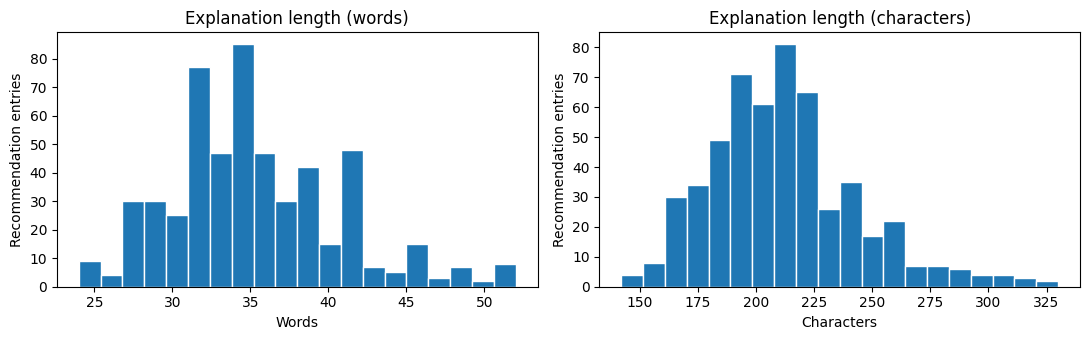

In [25]:
# plot

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, column, label in zip(axes, ["word_count", "character_count"], ["Words", "Characters"]):
    ax.hist(analysis_df[column], bins=20, edgecolor="white")
    ax.set(xlabel=label, ylabel="Recommendation entries", title=f"Explanation length ({label.lower()})")
plt.tight_layout()
plt.show()

### b-c-1 Preprocessing raw data for further analysis

 (Run ONLY Once, and store the result for future use)

compose records for recommendation explanations, recipes and personas (raw text for now).

In [26]:
explanation_records, recipe_records, persona_records = build_text_records(
    recommendations,
    recipes,
    personas_df,
)


compose lemmatized text of the former records

In [27]:
explanation_lemmas_df = make_lemma_table(explanation_records)
recipe_lemmas_df = make_lemma_table(recipe_records)
persona_lemmas_df = make_lemma_table(persona_records)

explanation_lemmas_df["rank"] = (
    explanation_lemmas_df["rank"].astype("Int64")
)

assert explanation_lemmas_df["recommendation_id"].is_unique
assert len(explanation_lemmas_df) == len(recommendations_df)

save results for future use

In [28]:
# store the processed text for future use
processed_dir.mkdir(parents=True, exist_ok=True)


explanation_lemmas_df.to_parquet(
    processed_dir / "explanation_lemmas.parquet",
    index=False
)
recipe_lemmas_df.to_parquet(
    processed_dir / "recipe_lemmas.parquet",
    index=False
)
persona_lemmas_df.to_parquet(
    processed_dir / "persona_lemmas.parquet",
    index=False
)

print("Saved processed files to:", processed_dir)
print("Explanation records:", len(explanation_lemmas_df))
print("Recipe text items:", len(recipe_lemmas_df))
print("Persona text items:", len(persona_lemmas_df))

display(
    explanation_lemmas_df[
        [
            "recommendation_id",
            "persona_id",
            "recipe_id",
            "rank",
            "explanation_lemmas"
        ]
    ].head()
)

display(
    recipe_lemmas_df.loc[
        recipe_lemmas_df["source_field"].eq("recipe_ingredient"),
        ["recipe_id", "recipe_text_lemmas"]
    ].head()
)

Saved processed files to: /content/drive/MyDrive/XFoodRec_Project_Data/processed
Explanation records: 536
Recipe text items: 8113
Persona text items: 530


,recommendation_id,persona_id,recipe_id,rank,explanation_lemmas
0,user_01_rank_01,user_01,81968,1,"[chickpea, spinach, greek, fantastic, choice, ..."
1,user_01_rank_02,user_01,10614,2,"[refried, beans, offer, high, protein, content..."
2,user_01_rank_03,user_01,94673,3,"[egyptian, red, lentil, soup, rich, protein, f..."
3,user_01_rank_04,user_01,364252,4,"[favorite, sauteed, kale, nutrient, dense, opt..."
4,user_01_rank_05,user_01,12569,5,"[hearty, black, beans, rice, combine, protein,..."


,recipe_id,recipe_text_lemmas
1,113861,"[cub, steak]"
2,113861,[oil]
3,113861,[butter]
4,113861,[flour]
5,113861,[salt]


Save token tables and nutrition field names

In [29]:
# build the three token tables from the same records as the lemma tables.
recommendation_tokens_df = make_token_table(explanation_records)
recipe_tokens_df = make_token_table(recipe_records)
persona_tokens_df = make_token_table(persona_records)

for filename, table in [
    ("recommendation_tokens.parquet", recommendation_tokens_df),
    ("recipe_tokens.parquet", recipe_tokens_df),
    ("persona_tokens.parquet", persona_tokens_df),
]:
    table.to_parquet(processed_dir / filename, index=False)
    print(f"Saved {filename}: {len(table)} text items")

display(recommendation_tokens_df[["recommendation_id", "text", "tokens"]].head())

Saved recommendation_tokens.parquet: 536 text items
Saved recipe_tokens.parquet: 8113 text items
Saved persona_tokens.parquet: 530 text items


,recommendation_id,text,tokens
0,user_01_rank_01,Chickpeas With Spinach (Greek) is a fantastic ...,"[Chickpeas, With, Spinach, (, Greek, ), is, a,..."
1,user_01_rank_02,"Refried Beans offers a high protein content, m...","[Refried, Beans, offers, a, high, protein, con..."
2,user_01_rank_03,Egyptian Red Lentil Soup is rich in protein an...,"[Egyptian, Red, Lentil, Soup, is, rich, in, pr..."
3,user_01_rank_04,My Favorite Sauteed Kale is a nutrient-dense o...,"[My, Favorite, Sauteed, Kale, is, a, nutrient,..."
4,user_01_rank_05,Hearty Black Beans & Rice combines protein-ric...,"[Hearty, Black, Beans, &, Rice, combines, prot..."


In [30]:
# collect actual nutrition keys rather than maintaining a separate word list.
nutrition_fields = list(dict.fromkeys(
    field
    for item in recommendations
    for recommendation in item["recommendations"]
    for field in recommendation["nutrition"]
))
nutrition_fields_path = processed_dir / "nutrition_fields.json"
with nutrition_fields_path.open("w", encoding="utf-8") as f:
    json.dump(nutrition_fields, f, ensure_ascii=False, indent=2)

print("Saved nutrition fields:", nutrition_fields)

Saved nutrition fields: ['calories', 'protein', 'carbs', 'fat']


### b-c-2 reload preprocessed data

In [31]:
explanation_lemmas_df = pd.read_parquet(processed_dir / "explanation_lemmas.parquet")
recipe_lemmas_df = pd.read_parquet(processed_dir / "recipe_lemmas.parquet")
persona_lemmas_df = pd.read_parquet(processed_dir / "persona_lemmas.parquet")
nutrition_fields_path = processed_dir / "nutrition_fields.json"

print("Explanations:", len(explanation_lemmas_df))
print("Recipe text items:", len(recipe_lemmas_df))
print("Persona text items:", len(persona_lemmas_df))


Explanations: 536
Recipe text items: 8113
Persona text items: 530


Persisted file schemas and shared-helper behavior are documented in `data_exploration_readme.md`

In [32]:
recipe_table = recipes
with open(nutrition_fields_path, "r", encoding="utf-8") as f:
    nutrition_fields = json.load(f)
matching_resources = build_matching_resources(persona_lemmas_df, recipe_lemmas_df, recipe_table, nutrition_fields)
print("Nutrients recorded in the data:", matching_resources["nutrient_terms"])
print("Health label values (goals, diets, conditions):", len(matching_resources["health_label_values"]))
print("Personas with values:", len(matching_resources["persona_values"]))
print("Recipes with ingredient names:", len(matching_resources["ingredient_names"]),
      "| food words:", len(matching_resources["food_terms"]))

Nutrients recorded in the data: ['calorie', 'carb', 'carbohydrate', 'cholesterol', 'fat', 'fiber', 'protein', 'sodium', 'sugar']
Health label values (goals, diets, conditions): 60
Personas with values: 40
Recipes with ingredient names: 702 | food words: 705


### c. Distribution of explanation types (ingredient-, nutrition-, taste-focused)

#### c.1. Classify explanations by focus


In [33]:
nutrition_terms = set(matching_resources["nutrient_terms"])
taste_terms = {
    "taste", "flavor", "flavour", "delicious", "tasty",
    "savory", "savoury", "sweet", "spicy", "tangy",
    "creamy", "crunchy", "crispy", "tender", "juicy",
    "aromatic", "refreshing", "hearty", "satisfy",
    "comfort", "warm", "mild", "bitter", "sour", "smoky",
    "texture",
}

analysis_df = explanation_lemmas_df.copy()
ingredient_matches = []
nutrition_matches = []
taste_matches = []

for row in analysis_df.to_dict("records"):
    explanation_body = explanation_words(row, matching_resources)
    explanation_terms = set(explanation_body)
    recipe_ingredients = matching_resources["ingredient_names"].get(
        str(row["recipe_id"]),
        set(),
    )

    ingredient_matches.append(sorted(
        " ".join(ingredient)
        for ingredient in recipe_ingredients
        if contains_sequence(explanation_body, list(ingredient))
    ))
    nutrition_matches.append(sorted(
        nutrient
        for nutrient in nutrition_terms
        if any(term_matches(term, nutrient) for term in explanation_body)
    ))
    taste_matches.append(sorted(explanation_terms & taste_terms))

analysis_df["ingredient_matches"] = ingredient_matches
analysis_df["nutrition_matches"] = nutrition_matches
analysis_df["taste_matches"] = taste_matches
analysis_df["ingredient_focused"] = analysis_df["ingredient_matches"].map(bool)
analysis_df["nutrition_focused"] = analysis_df["nutrition_matches"].map(bool)
analysis_df["taste_focused"] = analysis_df["taste_matches"].map(bool)

focus_columns = [
    "ingredient_focused",
    "nutrition_focused",
    "taste_focused",
]
focus_labels = {
    "ingredient_focused": "Ingredient",
    "nutrition_focused": "Nutrition",
    "taste_focused": "Taste",
}

total_explanations = len(analysis_df)
if total_explanations == 0:
    raise ValueError("No explanation records were loaded.")
if not analysis_df[focus_columns].any(axis=None):
    raise ValueError(
        "No focus matches were found. Check the loaded lemmas and vocabularies."
    )


#### c.2. Summarize focus categories


In [34]:
type_summary = pd.DataFrame({
    "count": analysis_df[focus_columns].sum().astype(int),
    "percent": analysis_df[focus_columns].mean().mul(100).round(1),
})
type_summary.index = [focus_labels[column] for column in type_summary.index]
display(type_summary)

analysis_df["focus_combination"] = analysis_df.apply(
    focus_combination,
    axis=1,
)
combination_summary = (
    analysis_df["focus_combination"]
    .value_counts()
    .rename_axis("focus_combination")
    .to_frame("count")
)
combination_summary["percent"] = (
    combination_summary["count"]
    .div(total_explanations)
    .mul(100)
    .round(1)
)
display(combination_summary)


,count,percent
Ingredient,209,39.0
Nutrition,496,92.5
Taste,371,69.2


,count,percent
focus_combination,,
Nutrition + Taste,210,39.2
Ingredient + Nutrition + Taste,130,24.3
Nutrition,101,18.8
Ingredient + Nutrition,55,10.3
Ingredient + Taste,21,3.9
Taste,10,1.9
No detected focus,6,1.1
Ingredient,3,0.6


#### c.3. Visualize focus categories


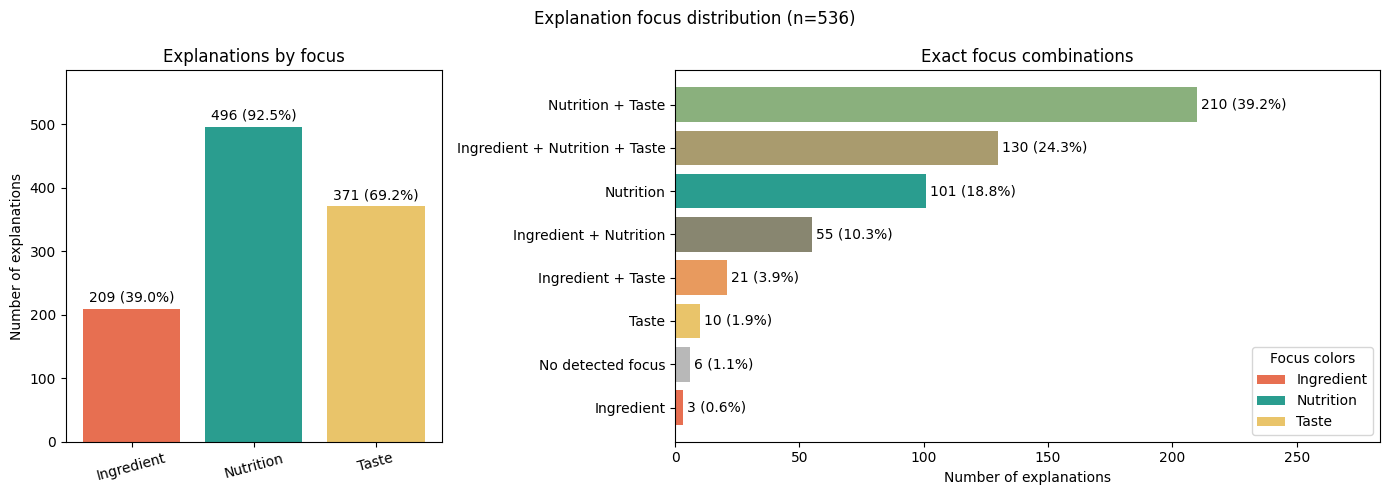

In [35]:
from matplotlib.patches import Patch

focus_colors = {
    "Ingredient": "#E76F51",
    "Nutrition": "#2A9D8F",
    "Taste": "#E9C46A",
}

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5),
    gridspec_kw={"width_ratios": [0.8, 1.5]},
)

left_labels = ["Ingredient", "Nutrition", "Taste"]
left_counts = [int(analysis_df[column].sum()) for column in focus_columns]
left_percentages = [100 * count / total_explanations for count in left_counts]
bars = axes[0].bar(
    left_labels,
    left_counts,
    color=[focus_colors[label] for label in left_labels],
)
axes[0].bar_label(
    bars,
    labels=[
        f"{count} ({percentage:.1f}%)"
        for count, percentage in zip(left_counts, left_percentages)
    ],
    padding=3,
)
axes[0].set_title("Explanations by focus")
axes[0].set_ylabel("Number of explanations")
axes[0].set_ylim(0, max(left_counts) * 1.18)
axes[0].tick_params(axis="x", rotation=15)

plot_data = combination_summary.sort_values("count")
combination_labels = plot_data.index.tolist()
combination_counts = plot_data["count"].tolist()
combination_percentages = plot_data["percent"].tolist()
bars = axes[1].barh(
    combination_labels,
    combination_counts,
    color=[color_for_combination(label) for label in combination_labels],
)
axes[1].bar_label(
    bars,
    labels=[
        f"{count} ({percentage:.1f}%)"
        for count, percentage in zip(combination_counts, combination_percentages)
    ],
    padding=3,
)
axes[1].set_title("Exact focus combinations")
axes[1].set_xlabel("Number of explanations")
axes[1].set_xlim(0, max(combination_counts) * 1.35)
axes[1].legend(
    handles=[
        Patch(facecolor=color, label=label)
        for label, color in focus_colors.items()
    ],
    title="Focus colors",
    loc="lower right",
)

fig.suptitle(f"Explanation focus distribution (n={total_explanations})")
plt.tight_layout()
plt.show()


#### c.4. Inspect matched terms


In [36]:
display(
    analysis_df[
        [
            "recommendation_id",
            "ingredient_matches",
            "nutrition_matches",
            "taste_matches",
            "focus_combination",
        ]
    ].head(15)
)


,recommendation_id,ingredient_matches,nutrition_matches,taste_matches,focus_combination
0,user_01_rank_01,"[chickpea, spinach]",[protein],"[satisfy, taste]",Ingredient + Nutrition + Taste
1,user_01_rank_02,[bean],"[fat, protein]",[hearty],Ingredient + Nutrition + Taste
2,user_01_rank_03,[lentil],"[fiber, protein]",[warm],Ingredient + Nutrition + Taste
3,user_01_rank_04,[oil],"[calorie, fat]",[],Ingredient + Nutrition
4,user_01_rank_05,[bean],"[carb, carbohydrate, protein]",[satisfy],Ingredient + Nutrition + Taste
5,user_01_rank_06,[bean],"[fiber, protein]",[],Ingredient + Nutrition
6,user_01_rank_07,[],"[calorie, protein]","[flavor, hearty]",Nutrition + Taste
7,user_01_rank_08,[bean],"[fiber, protein]",[],Ingredient + Nutrition
8,user_01_rank_09,[],[protein],[satisfy],Nutrition + Taste
9,user_01_rank_10,[],"[carb, carbohydrate, protein]",[],Nutrition


### d. Coverage of user preferences vs. health justification

Each explanation is checked for two things: whether it refers to the user's preferences, and whether it gives a health justification. One explanation can count as both, one, or neither. Only things that exist in the data count.

| What the explanation mentions | Counted as |
|---|---|
| The user's own liked or disliked ingredients or favourite cuisines (e.g. "lentils, which you enjoy", or "features chicken" for a user who likes chicken) | Preference |
| A nutrient recorded in the recipe data, with or without numbers (e.g. "high in protein", "33.1 g of protein", "low in sodium") | Health |
| A goal, diet or health condition from the user profiles (e.g. "weight loss", "vegan", "low sodium") | Health |
| An allergen, only for the user who has that allergy | Health |
| General wording that names none of the above (e.g. "fits your preferences", "suits your dietary needs", "healthy") | Neither (left to the transparency analysis) |

The recipe title is removed from the explanation before matching, so words that only appear in the title are not counted.

In [37]:
coverage_df = compute_coverage(
    explanation_lemmas_df,
    matching_resources,
)

existing_coverage_columns = [
    column
    for column in coverage_df.columns
    if column != "recommendation_id" and column in analysis_df.columns
]
analysis_df = (
    analysis_df
    .drop(columns=existing_coverage_columns)
    .merge(
        coverage_df,
        on="recommendation_id",
        how="left",
        validate="one_to_one",
    )
)


#### d.1. Summarize coverage


In [38]:
total_explanations = len(coverage_df)
coverage_order = [
    "Both",
    "Preference only",
    "Health only",
    "Neither",
]
coverage_summary = (
    coverage_df["coverage_group"]
    .value_counts()
    .reindex(coverage_order, fill_value=0)
    .rename("count")
    .to_frame()
)
coverage_summary["percent"] = (
    100 * coverage_summary["count"] / total_explanations
).round(1)
display(coverage_summary)

has_nutrition_evidence = coverage_df["nutrition_evidence"].map(bool)
has_health_evidence = coverage_df["health_evidence"].map(bool)
evidence_summary = pd.DataFrame(
    {
        "explanations": [
            coverage_df["preference_covered"].sum(),
            coverage_df["health_justification"].sum(),
            has_nutrition_evidence.sum(),
            has_health_evidence.sum(),
        ]
    },
    index=[
        "Preference: user's own ingredient or cuisine",
        "Health justification (any)",
        "  nutrient recorded in the recipe data",
        "  goal, diet, allergy or condition",
    ],
)
evidence_summary["percent"] = (
    100 * evidence_summary["explanations"] / total_explanations
).round(1)
display(evidence_summary)


,count,percent
coverage_group,,
Both,245,45.7
Preference only,19,3.5
Health only,264,49.3
Neither,8,1.5


,explanations,percent
Preference: user's own ingredient or cuisine,264,49.3
Health justification (any),509,95.0
nutrient recorded in the recipe data,496,92.5
"goal, diet, allergy or condition",292,54.5


#### d.2. Visualize coverage


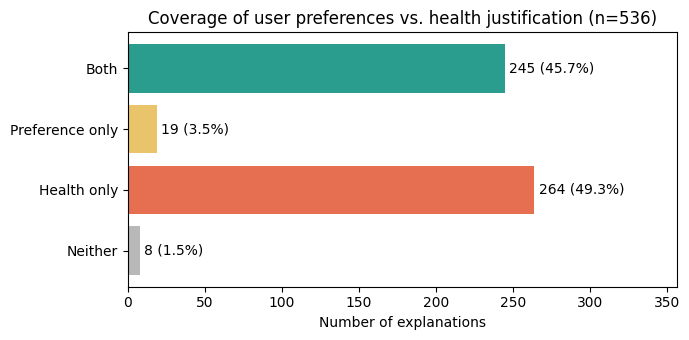

In [39]:
coverage_colors = {
    "Both": "#2A9D8F",
    "Preference only": "#E9C46A",
    "Health only": "#E76F51",
    "Neither": "#B8B8B8",
}
plot_order = coverage_order[::-1]
plot_counts = coverage_summary.loc[plot_order, "count"]
plot_colors = [coverage_colors[group] for group in plot_order]

fig, ax = plt.subplots(figsize=(7, 3.5))
bars = ax.barh(plot_order, plot_counts, color=plot_colors)
labels = [
    f"{count} ({count / total_explanations:.1%})"
    for count in plot_counts
]
ax.bar_label(bars, labels=labels, padding=3)
ax.set_xlabel("Number of explanations")
ax.set_title(
    "Coverage of user preferences vs. health justification "
    f"(n={total_explanations})"
)
ax.set_xlim(0, coverage_summary["count"].max() * 1.35)
plt.tight_layout()
plt.show()
